# MD3 · Pronóstico de serie temporal
### H&M Personalized Fashion Recommendations · Grupo 2 · Minería de Datos · Semana 12

**Modalidad:** `COMPLETA` · **Salida:** dos ZIP (evidencias y modelos) + notebook ejecutado.

**Objetivo:** recuentos diarios de registros, no ventas reales. **Métodos:** Naive, naive estacional, ETS y SARIMA.

**Ruta de lectura:** planteamiento → entorno → datos → exploración → diseño → variables → modelado → evaluación visual → test → interpretación → persistencia → auditoría/ZIP → conclusiones.

> **Integridad:** las pruebas P01–P04 conservan sus criterios originales. Un proceso `OK` sin patrones no equivale a evidencia de minería. Las decisiones se toman antes de abrir el test; los modelos de despliegue se distinguen de los evaluados. Los `.joblib` y `.pkl` solo deben cargarse desde fuentes confiables.


## 1. Planteamiento y alcance

**Pregunta de investigación:** ¿Qué aporta Naive, naive estacional, ETS y SARIMA para recuentos diarios de registros, no ventas reales?  Los experimentos P01–P04 se ejecutan y se evalúan bajo las particiones y reglas del protocolo aprobado.


## 2. Entorno reproducible y configuración

**Modo `COMPLETA`:** instalación condicional, semilla, firma de entradas, cachés y trazabilidad. Las salidas se escriben en `/kaggle/working/hm_modelamiento`.


In [1]:
import importlib.util,subprocess,sys
DEPENDENCIAS = [('duckdb', 'duckdb==1.3.2'), ('statsmodels', 'statsmodels>=0.14.0')]
missing=[pkg for module,pkg in DEPENDENCIAS if importlib.util.find_spec(module) is None]
if missing:
    print('Dependencias faltantes:', missing)
    try: subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
    except Exception as exc:
        raise RuntimeError('No se pudieron instalar dependencias. En Kaggle habilita Internet en Notebook Options, o adjunta ruedas compatibles.') from exc
else:print('Dependencias específicas ya instaladas.')


Dependencias específicas ya instaladas.


In [2]:
# Configuración portable: Kaggle primero, pero sin asumir rutas fijas.
from pathlib import Path
import os, json, time, platform, hashlib, warnings, sys
import numpy as np, pandas as pd
from packaging.version import Version
from importlib.metadata import version, PackageNotFoundError
import psutil
DATA_FILENAMES = {'transactions':'transacciones_preparadas.parquet',
                  'customers':'clientes_preparados.parquet',
                  'segmentation':'clientes_vista_segmentacion.parquet',
                  'articles':'articles_preparado.parquet'}
KAGGLE_CANDIDATE = Path('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados')
INPUT_DIR = Path(os.environ.get('HM_INPUT_DIR', str(KAGGLE_CANDIDATE)))
if not all((INPUT_DIR / x).is_file() for x in DATA_FILENAMES.values()):
    roots=[Path('/kaggle/input'), Path.cwd(), Path('/mnt/data')]
    found=[]
    for root in roots:
        if root.is_dir():
            for path in root.rglob('transacciones_preparadas.parquet'):
                if all((path.parent / fn).is_file() for fn in DATA_FILENAMES.values()): found.append(path.parent.resolve())
    found=list(dict.fromkeys(found))
    if len(found)!=1: raise FileNotFoundError(f'Esperado un único directorio con los cuatro Parquet. Encontrados: {found}. Defina HM_INPUT_DIR.')
    INPUT_DIR=found[0]
FILES={k:INPUT_DIR / v for k,v in DATA_FILENAMES.items()}
OUTPUT_ROOT=Path(os.environ.get('HM_OUTPUT_DIR','/kaggle/working/hm_modelamiento' if Path('/kaggle/working').is_dir() else str(Path.cwd()/'hm_modelamiento')))
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
print('Datos:',INPUT_DIR,'RAM disponible GiB:',round(psutil.virtual_memory().available/2**30,2))
print('CPU lógicas:',os.cpu_count(),'Python:',sys.version.split()[0])
print({k:(str(v), round(v.stat().st_size/2**20,1)) for k,v in FILES.items()})
def _has_pkg(n):
    try:version(n);return True
    except PackageNotFoundError:return False
try:
    import duckdb
except ImportError as exc:
    raise RuntimeError('Falta duckdb. En Kaggle: habilitar instalación si es necesaria y ejecutar %pip install duckdb==1.3.2') from exc
con=duckdb.connect(database=':memory:')
con.execute('PRAGMA threads=4')
con.execute("SET memory_limit='8GB'")
PTRANS=str(FILES['transactions']).replace("'", "''")
PART=str(FILES['articles']).replace("'", "''")
PCUST=str(FILES['customers']).replace("'", "''")
PSEG=str(FILES['segmentation']).replace("'", "''")

OUT=OUTPUT_ROOT/'md3';OUT.mkdir(parents=True,exist_ok=True)
def save_csv(df, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(df).to_csv(p,index=False); print('Guardado:',p); return p

def save_json(obj, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    p.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
    print('Guardado:',p);return p

def sha256_path(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()

SOURCE={'sha256':{k:sha256_path(v) for k,v in FILES.items()},'runtime':platform.platform(),'python':sys.version.split()[0],
        'packages':{n:(version(n) if _has_pkg(n) else None) for n in ['numpy','pandas','scikit-learn','statsmodels','duckdb']}}
save_json(SOURCE,'entrada_y_entorno.json')
STATUS=[]
def registro(prueba,etapa,estado,detalle='',duracion_s=None):
    item={'prueba':prueba,'etapa':etapa,'estado':estado,'detalle':str(detalle),'duracion_s':duracion_s}
    STATUS.append(item)
    pd.DataFrame(STATUS).to_csv(OUT/'estado_experimentos.csv',index=False)
    return item


Datos: /kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados RAM disponible GiB: 30.0
CPU lógicas: 4 Python: 3.13.18
{'transactions': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/transacciones_preparadas.parquet', 448.3), 'customers': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_preparados.parquet', 160.2), 'segmentation': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_vista_segmentacion.parquet', 80.4), 'articles': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/articles_preparado.parquet', 16.9)}
Guardado: /kaggle/working/hm_modelamiento/md3/entrada_y_entorno.json


In [3]:

# Cache cannot be silently reused with a different set of input files.
INPUT_SIGNATURE = SOURCE['sha256']
p_input = OUT / 'origen_cache.json'
if p_input.exists():
    old = json.loads(p_input.read_text(encoding='utf-8'))
    if old.get('sha256') != INPUT_SIGNATURE:
        raise RuntimeError('El origen cambió respecto a los cachés previos. Usar un nuevo HM_OUTPUT_DIR o depurar cachés de forma controlada.')
else:
    p_input.write_text(json.dumps({'sha256':INPUT_SIGNATURE},indent=2),encoding='utf-8')


In [4]:
# Monitor auxiliar, transversal y no intrusivo (no altera las estimaciones).
import threading, time as _hm_time, psutil as _hm_psutil
_HM_MONITOR=None
def hm_monitor_inicio(etapa, cada=30):
    global _HM_MONITOR
    hm_monitor_fin()
    e=threading.Event(); t0=_hm_time.monotonic(); proc=_hm_psutil.Process()
    def loop():
        while not e.wait(cada):
            try:
                print(f'[PROGRESO] {etapa} | {_hm_time.monotonic()-t0:.0f} s | RAM proceso {proc.memory_info().rss/2**30:.2f} GiB', flush=True)
            except Exception: return
    t=threading.Thread(target=loop,daemon=True); t.start();_HM_MONITOR=(e,t,t0,etapa)
    print(f'[INICIO] {etapa}',flush=True)
def hm_monitor_fin():
    global _HM_MONITOR
    if _HM_MONITOR is not None:
        ev,t,t0,label=_HM_MONITOR; ev.set();t.join(timeout=1)
        print(f'[FIN] {label}: {_hm_time.monotonic()-t0:.1f} s',flush=True)
        _HM_MONITOR=None


## 3. Carga y validación de datos

Validar las fuentes reales. No sustituir errores de entrada por muestras sintéticas.


In [5]:
P_SERIES=OUT/'series_diarias_cache.parquet'
if not P_SERIES.exists():
    con.execute(f"""COPY (
        SELECT t_dat::DATE AS fecha, COUNT(*)::BIGINT AS registros,
        SUM(CASE WHEN sales_channel_id='1' THEN 1 ELSE 0 END)::BIGINT AS canal_1,
        SUM(CASE WHEN sales_channel_id='2' THEN 1 ELSE 0 END)::BIGINT AS canal_2
        FROM read_parquet('{PTRANS}') GROUP BY 1 ORDER BY 1
    ) TO '{str(P_SERIES).replace(chr(39),chr(39)*2)}' (FORMAT PARQUET)""")
serie=con.execute(f"SELECT * FROM read_parquet('{str(P_SERIES)}') ORDER BY fecha").df()
serie['fecha']=pd.to_datetime(serie['fecha'])
assert len(serie)==734 and serie.fecha.min()==pd.Timestamp('2018-09-20') and serie.fecha.max()==pd.Timestamp('2020-09-22')
assert serie.fecha.is_unique and serie.fecha.diff().iloc[1:].eq(pd.Timedelta(days=1)).all()
assert serie.registros.sum()==31_788_324
assert (serie.registros==serie.canal_1+serie.canal_2).all()
assert (serie[['registros','canal_1','canal_2']]>=0).all().all()
serie.to_csv(OUT/'serie_diaria_y_canales.csv',index=False)
fechas=serie.fecha
val_ini=pd.Timestamp('2020-02-15'); test_ini=pd.Timestamp('2020-06-04')
assert (fechas<val_ini).sum()==513 and ((fechas>=val_ini)&(fechas<test_ini)).sum()==110 and (fechas>=test_ini).sum()==111
print('Serie conciliada:',len(serie),'días, registros=',serie.registros.sum())
registro('MD3-P03','entrada','PASS','734 días y canales conciliados')


Serie conciliada: 734 días, registros= 31788324


{'prueba': 'MD3-P03',
 'etapa': 'entrada',
 'estado': 'PASS',
 'detalle': '734 días y canales conciliados',
 'duracion_s': None}

## 4. Exploración orientada al modelado

**Lectura:** examina distribuciones y cobertura antes de ajustar, sin imprimir identificadores individuales.


**Resumen de la serie diaria**

,registros,canal_1,canal_2
count,734.00,734.00,734.00
mean,43308.34,12818.07,30490.28
std,17075.03,7358.53,13884.76
min,12760.00,0.00,7945.00
25%,33935.75,8125.75,23597.25
50%,39515.50,12220.00,27691.00
75%,47447.50,16909.50,33681.25
max,198622.00,77428.00,168688.00


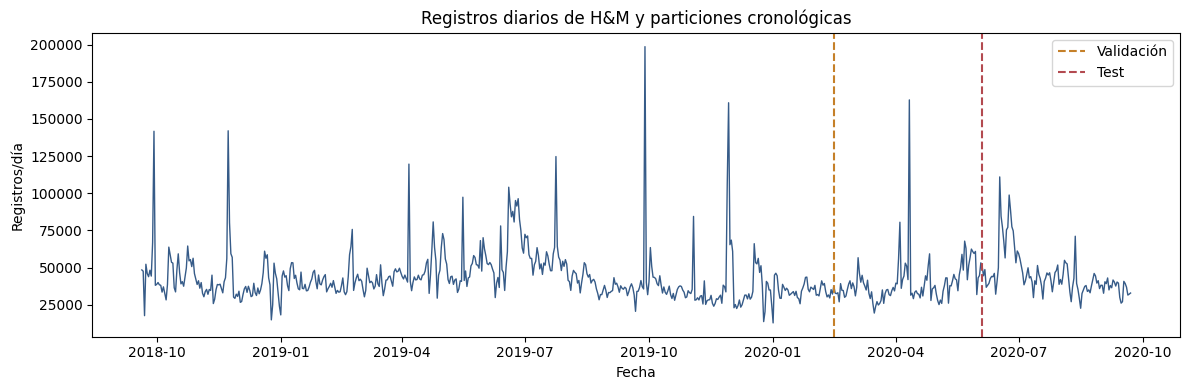

In [6]:
# Exploración visual de la serie; no altera las particiones.
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
display(Markdown('**Resumen de la serie diaria**'))
display(serie[['registros','canal_1','canal_2']].describe().round(2))
fig,ax=plt.subplots(figsize=(12,4));ax.plot(serie['fecha'],serie['registros'],lw=1,color='#365b88')
ax.axvline(serie.fecha.iloc[513],color='#c58029',ls='--',label='Validación')
ax.axvline(serie.fecha.iloc[623],color='#b34a50',ls='--',label='Test')
ax.set(title='Registros diarios de H&M y particiones cronológicas',xlabel='Fecha',ylabel='Registros/día')
ax.legend();fig.tight_layout();fig.savefig(OUT/'md3_exploracion_serie.png',dpi=135);plt.show();plt.close(fig)


## 5. Diseño experimental y criterios de evaluación

**Métodos:** Naive, naive estacional, ETS y SARIMA. **Pruebas:** MD3-P01 a MD3-P04. La selección se decide con desarrollo/validación; test solo evalúa. Los estados incompletos se reportan, nunca se sustituyen por métricas ficticias.


## 6. Preparación de variables, matrices y particiones

Transformaciones reproducibles y particiones congeladas antes de evaluación retenida.


In [7]:
def origins(part, horizon):
    start=513 if part=='validacion' else 623
    end=623 if part=='validacion' else len(serie)
    return [i for i in range(start-1,end-horizon,7)]
for part in ('validacion','test'):
    assert len(origins(part,7))==15, (part,origins(part,7))
    assert len(origins(part,28))==12
assert serie.fecha.iloc[origins('validacion',7)[-1]]==pd.Timestamp('2020-05-22')
assert serie.fecha.iloc[origins('test',7)[-1]]==pd.Timestamp('2020-09-09')

def baselines(train,h):
    a=np.asarray(train,dtype=float)
    return {'naive':np.repeat(a[-1],h), 'snaive7':np.resize(a[-7:],h)}
def evaluar(obs,pred,train):
    obs=np.asarray(obs,dtype=float); pred=np.maximum(0,np.asarray(pred,dtype=float))
    err=obs-pred
    denom=np.abs(np.asarray(train)[7:]-np.asarray(train)[:-7]).mean() if len(train)>7 else np.nan
    return {'mae':float(np.abs(err).mean()),'rmse':float(np.sqrt(np.square(err).mean())),
            'sesgo':float(err.mean()),'mase7':float(np.abs(err).mean()/denom) if denom>0 else np.nan}

def metricas_agregadas(df):
    err=df['observado'].to_numpy()-df['prediccion'].to_numpy()
    return {'mae':float(np.abs(err).mean()),'rmse':float(np.sqrt(np.mean(err**2)))}

def tabla_baselines(y,part,h=7):
    res=[]
    for o in origins(part,h):
        preds=baselines(y[:o+1],h)
        for name,p in preds.items():
            for step,(real,yp) in enumerate(zip(y[o+1:o+1+h],p),1):
                res.append({'fase':part,'origen':str(serie.fecha.iloc[o].date()),'objetivo':str(serie.fecha.iloc[o+step].date()),
                'paso':step,'modelo':name,'observado':float(real),'prediccion':float(yp),'prediccion_bruta':float(yp)})
    return pd.DataFrame(res)
y=serie.registros.to_numpy(dtype=float)
bas_val=tabla_baselines(y,'validacion')
base_metrics={name:metricas_agregadas(g) for name,g in bas_val.groupby('modelo')}
a=base_metrics['naive']['mae']; b=base_metrics['snaive7']['mae']
BSTAR='naive' if (np.isclose(a,b,rtol=1e-12,atol=1e-12) or a<b) else 'snaive7'
save_csv(bas_val,'md3_baselines_validacion.csv')
save_json({'Bstar':BSTAR,'metricas':base_metrics},'baseline_fijada.json')
print('Baseline elegida solo en validación:', BSTAR,base_metrics)
registro('MD3-P01','baselines_validacion','PASS',BSTAR)


Guardado: /kaggle/working/hm_modelamiento/md3/md3_baselines_validacion.csv
Guardado: /kaggle/working/hm_modelamiento/md3/baseline_fijada.json
Baseline elegida solo en validación: naive {'naive': {'mae': 7969.704761904762, 'rmse': 14817.561623515074}, 'snaive7': {'mae': 10476.609523809524, 'rmse': 18984.82032572339}}


{'prueba': 'MD3-P01',
 'etapa': 'baselines_validacion',
 'estado': 'PASS',
 'detalle': 'naive',
 'duracion_s': None}

## 7. Modelamiento y selección

Se ejecuta el protocolo completo, con guardado progresivo. Las técnicas no admiten resultados inventados en caso de timeout.


In [8]:
import itertools, multiprocessing as mp, queue, traceback
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels import __version__ as statsmodels_version
ETS_CFG=[]
for trend in (None,'add'):
    for seasonal in (None,'add'):
        damping=(False,True) if trend=='add' else (False,)
        for damped in damping:
            ETS_CFG.append({'family':'ETS','trend':trend,'seasonal':seasonal,'damped':damped,
            'name':f"ETS_t{trend or 'N'}_s{seasonal or 'N'}_d{int(damped)}"})
assert len(ETS_CFG)==6
SAR_CFG=[]
for p,q,P,Q in itertools.product((0,1),repeat=4):
    for d,D in ((0,0),(1,0),(0,1)):
        SAR_CFG.append({'family':'SARIMA','order':(p,d,q),'seasonal_order':(P,D,Q,7),
            'name':f'SARIMA_{p}{d}{q}_{P}{D}{Q}_7'})
assert len(SAR_CFG)==48
CONFIG={cfg['name']:cfg for cfg in ETS_CFG+SAR_CFG}
# Los resultados del proceso externo se serializan en JSON y se reutilizan por hash+origen+estructura.
CACHE=OUT/'cache_ajustes';CACHE.mkdir(exist_ok=True)
RAM_MAX=min(6*2**30,round(.7*psutil.virtual_memory().available))

def _fit_worker(cfg, train, horizon, q):
    import warnings, time, traceback
    t0=time.monotonic()
    try:
        with warnings.catch_warnings(record=True) as wr:
            warnings.simplefilter('always')
            if cfg['family']=='ETS':
                kw=dict(error='add',trend=cfg['trend'],seasonal=cfg['seasonal'],
                        damped_trend=cfg['damped'],initialization_method='estimated')
                if cfg['seasonal']: kw['seasonal_periods']=7
                model=ETSModel(train,**kw)
                fit=model.fit(maxiter=500,disp=False)  # ETSModel usa L-BFGS interno
                forecast=np.asarray(fit.forecast(horizon),dtype=float)
            else:
                d=cfg['order'][1];D=cfg['seasonal_order'][1]
                model=SARIMAX(train,order=cfg['order'],seasonal_order=cfg['seasonal_order'],
                    trend='c' if d+D==0 else 'n',exog=None,simple_differencing=False,
                    use_exact_diffuse=True,enforce_stationarity=True,
                    enforce_invertibility=True,concentrate_scale=False)
                fit=model.fit(method='lbfgs',maxiter=500,disp=False)
                forecast=np.asarray(fit.forecast(horizon),dtype=float)
            params=np.asarray(fit.params,dtype=float)
            success=bool(getattr(fit,'mle_retvals',{}).get('converged',True))
            llf=float(fit.llf); k=float(getattr(fit,'df_model',len(params)))
            nobs=int(getattr(fit,'nobs_effective',len(train)))
            burn=int(getattr(fit,'loglikelihood_burn',0))
            sigma=float(getattr(fit,'scale',np.var(getattr(fit,'resid',train))))
            if cfg['family']=='SARIMA' and hasattr(fit,'filter_results'):
                # En SARIMAX con concentrate_scale=False la sigma2 estimada es último parámetro.
                if 'sigma2' in fit.param_names:sigma=float(params[fit.param_names.index('sigma2')])
            valid=(success and np.all(np.isfinite(params)) and np.isfinite(llf) and
                   np.all(np.isfinite(forecast)) and np.isfinite(sigma) and sigma>0)
            if cfg['family']=='SARIMA':
                valid=valid and bool(getattr(fit,'arroots',np.array([2.])) .__len__()==0 or np.all(np.abs(fit.arroots)>1-1e-8))
                valid=valid and bool(len(fit.maroots)==0 or np.all(np.abs(fit.maroots)>1-1e-8))
            out={'estado':'OK' if valid else 'INVALIDO','config':cfg['name'],'pred':forecast.tolist(),
                'llf':llf,'k':k,'nobs_effective':nobs,'loglikelihood_burn':burn,
                'converged':success,'sigma':sigma,'segundos':time.monotonic()-t0,
                'warnings':[str(x.message) for x in wr],
                'residuos':np.asarray(fit.resid,dtype=float).tolist()}
            q.put(out)
    except Exception as exc:
        q.put({'estado':'FALLO','config':cfg['name'],'error':repr(exc),'trace':traceback.format_exc(),
               'segundos':time.monotonic()-t0})

def fit_safe(name,train,hor=28,limite=60):
    cfg=CONFIG[name]
    raw=np.asarray(train,dtype='float64')
    fp=hashlib.sha256(raw.tobytes()+statsmodels_version.encode()+b'protocol_v2_diagnostics'+repr(cfg).encode()+str(hor).encode()).hexdigest()
    dst=CACHE/(fp+'.json')
    if dst.exists():
        x=json.loads(dst.read_text());x['cache_hit']=True;return x
    ctx=mp.get_context('fork')
    q=ctx.Queue();p=ctx.Process(target=_fit_worker,args=(cfg,raw,hor,q))
    start=time.monotonic();p.start();peak=0;status=None
    while p.is_alive():
        try:
            proc=psutil.Process(p.pid);peak=max(peak,proc.memory_info().rss)
        except psutil.NoSuchProcess:break
        if peak>RAM_MAX:status='MEMORIA';break
        if time.monotonic()-start>limite:status='TIMEOUT';break
        p.join(.15)
    if p.is_alive():p.terminate();p.join(3)
    try:out=q.get(timeout=1) if status is None else {'estado':status,'config':name}
    except queue.Empty:out={'estado':'FALLO','config':name,'error':'worker sin respuesta'}
    out['rss_max_bytes']=peak;out['cache_hit']=False
    dst.write_text(json.dumps(out,ensure_ascii=False,default=str))
    with (OUT/'bitacora_ajustes.jsonl').open('a') as f:f.write(json.dumps(out,ensure_ascii=False,default=str)+'\n')
    return out
print('ETS:',len(ETS_CFG),'SARIMA:',len(SAR_CFG),'memoria máxima por proceso:',round(RAM_MAX/2**30,2),'GiB')

ETS: 6 SARIMA: 48 memoria máxima por proceso: 6.0 GiB


In [9]:
print('[MD3] Piloto, 48 configuraciones SARIMA y validación: el código registra cada ajuste.',flush=True)

[MD3] Piloto, 48 configuraciones SARIMA y validación: el código registra cada ajuste.


In [10]:
RUN_PRINCIPAL = True  # Cambiar a False solo para validar baselines sin búsqueda.
PILOT_NAMES=['ETS_tN_sN_d0','ETS_tadd_sadd_d1',
 'SARIMA_000_000_7','SARIMA_101_101_7','SARIMA_111_101_7','SARIMA_101_111_7']
# El piloto no inventa duración para configuraciones fallidas o con timeout.
if RUN_PRINCIPAL:
    tmain=time.monotonic();val0=y[:513];pilot=[]
    for name in PILOT_NAMES:
        if time.monotonic()-tmain>600:
            registro('MD3-P02','piloto','INTERRUMPIDO','Límite de 10 minutos')
            RUN_PRINCIPAL=False
            break
        print('[MD3 PILOTO]',name,flush=True)
        r=fit_safe(name,val0,hor=28)
        pilot.append(r)
        save_csv([{k:v for k,v in x.items() if k not in ('pred','warnings','trace','residuos')}
                  for x in pilot],'md3_piloto.csv')
        if r.get('estado')!='OK' or not np.isfinite(r.get('segundos',np.nan)):
            registro('MD3-P02','piloto','INCOMPLETO',
                     {'configuracion':name,'estado':r.get('estado'),'error':r.get('error','')})
            RUN_PRINCIPAL=False
            break
        print(f"[MD3 PILOTO] {name}: {r['segundos']:.2f} s",flush=True)
    if RUN_PRINCIPAL and len(pilot)!=len(PILOT_NAMES):
        RUN_PRINCIPAL=False
        registro('MD3-P02','piloto','INCOMPLETO','No se completaron todas las configuraciones')
    if RUN_PRINCIPAL:
        mx={fam:max(x['segundos'] for x in pilot
                    if CONFIG[x['config']]['family']==fam) for fam in ('ETS','SARIMA')}
        projection=1.5*(48*mx['SARIMA']+15*(6*mx['ETS']+5*mx['SARIMA'])+30*max(mx.values()))
        save_json({'segundos_proyectados':projection,'limite_segundos':5400,
                   'piloto_n':len(pilot),'proyeccion_no_es_tiempo_real':True},
                  'proyeccion_presupuesto.json')
        if projection>5400:
            registro('MD3-P02','presupuesto','PAUSADO',
                     f'Proyección {projection/60:.1f} minutos >90; revisión metodológica requerida')
            RUN_PRINCIPAL=False
print('¿Continúa protocolo principal?',RUN_PRINCIPAL)


[MD3 PILOTO] ETS_tN_sN_d0
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] ETS_tN_sN_d0: 0.06 s
[MD3 PILOTO] ETS_tadd_sadd_d1
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] ETS_tadd_sadd_d1: 0.08 s
[MD3 PILOTO] SARIMA_000_000_7
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] SARIMA_000_000_7: 0.11 s
[MD3 PILOTO] SARIMA_101_101_7
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] SARIMA_101_101_7: 1.96 s
[MD3 PILOTO] SARIMA_111_101_7
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] SARIMA_111_101_7: 0.55 s
[MD3 PILOTO] SARIMA_101_111_7
Guardado: /kaggle/working/hm_modelamiento/md3/md3_piloto.csv
[MD3 PILOTO] SARIMA_101_111_7: 1.77 s
Guardado: /kaggle/working/hm_modelamiento/md3/proyeccion_presupuesto.json
¿Continúa protocolo principal? True


In [11]:
VALID_SAR=[]
if RUN_PRINCIPAL:
    for cfg in SAR_CFG:
        if time.monotonic()-tmain>5400:
            RUN_PRINCIPAL=False; registro('MD3-P02','preseleccion','PAUSADO','Presupuesto principal alcanzado');break
        r=fit_safe(cfg['name'],y[:513],hor=28)
        if r['estado']!='OK':continue
        k=float(r['k']);n=float(r['nobs_effective']);ll=float(r['llf'])
        aicc=(-2*ll+2*k)+(2*k*(k+1)/(n-k-1)) if n>k+1 else np.nan
        if np.isfinite(aicc):VALID_SAR.append({'name':cfg['name'],'aicc':aicc,'k':k,'n':n,'burn':r['loglikelihood_burn']})
    save_csv(VALID_SAR,'md3_sarima_aicc.csv')
    nvals={x['n'] for x in VALID_SAR}
    if len(nvals)>1:
        RUN_PRINCIPAL=False
        registro('MD3-P02','comparabilidad_AICc','PAUSADO','nobs_effective varía entre estructuras: revisar antes de ordenar')
    SAR_TOP=[v['name'] for v in sorted(VALID_SAR,key=lambda x:(x['aicc'],x['k'],x['name']))[:5]] if RUN_PRINCIPAL else []
else:SAR_TOP=[]
print('SARIMA preseleccionados:',SAR_TOP)


Guardado: /kaggle/working/hm_modelamiento/md3/md3_sarima_aicc.csv
SARIMA preseleccionados: ['SARIMA_101_111_7', 'SARIMA_001_011_7', 'SARIMA_101_011_7', 'SARIMA_100_011_7', 'SARIMA_100_111_7']


In [12]:
FORECAST_ROWS=[]; METRIC_ROWS=[]; FINALES={}; RECOMENDACION=None

def evaluar_candidato(name,part,y,hor=7,training_window=None):
    local=[];origin_metrics=[];errors=[]
    for o in origins(part,hor):
        train=y[:o+1] if training_window is None else y[max(0,o+1-training_window):o+1]
        predres=fit_safe(name,train,hor=max(28,hor))
        if predres['estado']!='OK':
            return None, None, {'config':name,'origen':o,'estado':predres['estado'],'error':predres.get('error','')}
        raw=np.asarray(predres['pred'][:hor],dtype=float); pred=np.maximum(0,raw)
        obs=y[o+1:o+1+hor]
        metr=evaluar(obs,pred,train)
        origin_metrics.append({'modelo':name,'fase':part,'origen':str(serie.fecha.iloc[o].date()),**metr})
        for h,(v,p,r) in enumerate(zip(obs,pred,raw),1):
            local.append({'fase':part,'origen':str(serie.fecha.iloc[o].date()),
              'objetivo':str(serie.fecha.iloc[o+h].date()),'modelo':name,'paso':h,
              'observado':float(v),'prediccion':float(p),'prediccion_bruta':float(r)})
    return pd.DataFrame(local),pd.DataFrame(origin_metrics),None

def preferido(stats,family):
    c=stats[stats.familia==family].copy()
    if c.empty:return None
    low=c.mae.min()
    ties=c[np.isclose(c.mae,0,atol=0,rtol=0)] if low==0 else c[(c.mae-low)/low*100<=1+1e-12]
    return ties.sort_values(['k','tiempo_s','name'],kind='stable').iloc[0]['name']

if RUN_PRINCIPAL:
    allc=ETS_CFG+[CONFIG[x] for x in SAR_TOP]
    for cfg in allc:
        if time.monotonic()-tmain>5400:
            RUN_PRINCIPAL=False; registro('MD3-P02','validacion','PAUSADO','Presupuesto 90 minutos');break
        name=cfg['name'];t0=time.monotonic()
        dt,ms,err=evaluar_candidato(name,'validacion',y)
        if err:
            registro('MD3-P02','candidato','INVALIDO',json.dumps(err));continue
        METRIC_ROWS.extend(ms.to_dict('records'));FORECAST_ROWS.extend(dt.to_dict('records'))
        v=metricas_agregadas(dt)
        FINALES[name]={'name':name,'familia':cfg['family'],'k':float(fit_safe(name,y[:513])['k']),
            'tiempo_s':time.monotonic()-t0,**v}
    save_csv(FORECAST_ROWS,'md3_pronosticos_validacion.csv')
    save_csv(METRIC_ROWS,'md3_metricas_por_origen.csv')
    save_csv(FINALES.values(),'md3_candidatos.csv')
    # Las configuraciones intentadas que no convergen se descartan tal como exige 3.4.
    # Solo una interrupción de presupuesto deja incompleta la búsqueda.
    if not RUN_PRINCIPAL:
        registro('MD3-P02','seleccion','INCONCLUSA','Búsqueda interrumpida; no se declara selección cerrada')
    elif not FINALES:
        registro('MD3-P02','seleccion','SIN_ALTERNATIVAS','Ninguna configuración ETS/SARIMA válida; se conserva B*')
    if RUN_PRINCIPAL:
        stats=pd.DataFrame(FINALES.values(),columns=['name','familia','k','tiempo_s','mae','rmse'])
        et=preferido(stats,'ETS');sa=preferido(stats,'SARIMA')
        bs=base_metrics[BSTAR]
        def criter(input_name):
            if input_name is None:return None
            x=FINALES[input_name]
            if bs['mae']==0:return {'cumple':False,'mejora_pct':None,'victorias':0}
            g=pd.DataFrame(METRIC_ROWS);ga=g[g.modelo==input_name].sort_values('origen')
            bg=bas_val[bas_val.modelo==BSTAR].groupby('origen',sort=True)
            byorigin=bg.apply(lambda z:float(np.abs(z.observado-z.prediccion).mean()))
            wins=int(sum(float(row.mae)<float(byorigin.loc[row.origen]) for row in ga.itertuples()))
            improvement=(bs['mae']-x['mae'])/bs['mae']*100
            return {'cumple':bool(improvement>=5 and x['rmse']<=bs['rmse'] and wins>=9),'mejora_pct':improvement,'victorias':wins}
        checks={k:criter(k) for k in (et,sa) if k}
        eligible=[k for k,v in checks.items() if v['cumple']]
        if eligible:
            minimal=min(FINALES[k]['mae'] for k in eligible)
            possible=[k for k in eligible if (FINALES[k]['mae']-minimal)*100/minimal<=1] if minimal else [k for k in eligible if FINALES[k]['mae']==0]
            RECOMENDACION=sorted(possible,key=lambda n:(FINALES[n]['k'],FINALES[n]['tiempo_s'],n))[0]
        else:RECOMENDACION=BSTAR
        finalistas=[v for v in (et,sa) if v]
        save_json({'Bstar':BSTAR,'ETS':et,'SARIMA':sa,'checks':checks,
          'recomendacion_validacion':RECOMENDACION,'finalistas':finalistas},'seleccion_congelada.json')
        registro('MD3-P02','seleccion','PASS',RECOMENDACION)
else:
    print('No se evalúan candidatos hasta tener el protocolo completo dentro del presupuesto.')


Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_validacion.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_metricas_por_origen.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_candidatos.csv
Guardado: /kaggle/working/hm_modelamiento/md3/seleccion_congelada.json


/tmp/ipykernel_50/3601089935.py:59: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  byorigin=bg.apply(lambda z:float(np.abs(z.observado-z.prediccion).mean()))
/tmp/ipykernel_50/3601089935.py:59: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  byorigin=bg.apply(lambda z:float(np.abs(z.observado-z.prediccion).mean()))


In [13]:
print('[MD3] Selección y validación terminadas.',flush=True)

[MD3] Selección y validación terminadas.


In [14]:
print('[MD3] Iniciando test y sensibilidades; las salidas se guardan progresivamente.',flush=True)

[MD3] Iniciando test y sensibilidades; las salidas se guardan progresivamente.


In [15]:
# MD3-P04: all secondary analyses use structures frozen ONLY by validation.
# They do not change recommendation after test has been opened.
if RUN_PRINCIPAL and RECOMENDACION is not None:
    saved=json.loads((OUT/'seleccion_congelada.json').read_text())
    finalistas=list(dict.fromkeys(saved['finalistas']))
    frames=[tabla_baselines(y,'test')]
    final_test_errors=[]
    for nm in finalistas:
        frame_test,metrics_test,err=evaluar_candidato(nm,'test',y)
        if err:final_test_errors.append(err);registro('MD3-P02','test','INCOMPLETO',err)
        else:frames.append(frame_test)
    test_all=pd.concat(frames,ignore_index=True)
    save_csv(test_all,'md3_pronosticos_test.csv')
    save_csv([{'modelo':n,**metricas_agregadas(g)} for n,g in test_all.groupby('modelo')],'md3_metricas_test.csv')
    registro('MD3-P03','rolling_origin_test','PASS' if not final_test_errors else 'INCOMPLETO',
        f'15 ventanas de horizonte 7, modelos faltantes: {len(final_test_errors)}')
    # Secondary 28-day horizon, channel-specific forecasts, limited 180-day training.
    t_secondary=time.monotonic();MAX_SECONDARY=1800
    SENS_SCENARIOS=[('h28','registros',28,None),('ultimos180','registros',7,180),
                    ('canal_1','canal_1',7,None),('canal_2','canal_2',7,None)]
    secondary=[]; forecasts=[]; incomplete=[]
    for label,col,h,window in SENS_SCENARIOS:
        yy=serie[col].to_numpy(dtype=float)
        for phase in ('validacion','test'):
            # Use matching baseline in each scenario. B* is frozen for the principal
            # comparison; channel baselines are descriptive, not additional selection.
            base_rows=tabla_baselines(yy,phase,h)
            if window is not None:
                custom=[]
                for origin in origins(phase,h):
                    z=baselines(yy[max(0,origin+1-window):origin+1],h)
                    for model,pred in z.items():
                        for step,(actual,pr) in enumerate(zip(yy[origin+1:origin+1+h],pred),1):
                            custom.append({'fase':phase,'origen':str(serie.fecha.iloc[origin].date()),
                               'objetivo':str(serie.fecha.iloc[origin+step].date()),'paso':step,
                               'modelo':model,'observado':float(actual),'prediccion':float(pr)})
                base_rows=pd.DataFrame(custom)
            for model,group in base_rows.groupby('modelo'):
                secondary.append({'ensayo':label,'fase':phase,'modelo':model,'h':h,
                  'ventanas':len(origins(phase,h)),'mae':metricas_agregadas(group)['mae'],
                  'rmse':metricas_agregadas(group)['rmse'],'estado':'OK'})
            forecasts.extend([{**r,'ensayo':label} for r in base_rows.to_dict('records')])
            for nm in finalistas:
                if time.monotonic()-t_secondary>MAX_SECONDARY:
                    incomplete.append({'ensayo':label,'fase':phase,'modelo':nm,'motivo':'BUDGET_30_MIN'});continue
                dt,origin_met,err=evaluar_candidato(nm,phase,yy,h,training_window=window)
                if err:
                    incomplete.append({'ensayo':label,'fase':phase,'modelo':nm,'motivo':err});continue
                sc=metricas_agregadas(dt)
                secondary.append({'ensayo':label,'fase':phase,'modelo':nm,'h':h,
                    'ventanas':len(origins(phase,h)),'mae':sc['mae'],'rmse':sc['rmse'],
                    'mase7':float(origin_met['mase7'].mean()) if len(origin_met) else np.nan,
                    'sesgo':float(origin_met['sesgo'].mean()) if len(origin_met) else np.nan,
                    'estado':'OK'})
                forecasts.extend([{**r,'ensayo':label} for r in dt.to_dict('records')])
            save_csv(secondary,'md3_sensibilidad.csv')
            save_csv(forecasts,'md3_pronosticos_sensibilidad.csv')
            save_json({'incompletos':incomplete,'segundos_consumidos':time.monotonic()-t_secondary},
                'md3_sensibilidad_estado.json')
    # Residuals from the training segment only, not forecast errors from test.
    diagnostics=[]
    from statsmodels.stats.diagnostic import acorr_ljungbox
    from statsmodels.tsa.stattools import acf
    for nm in finalistas:
        r=fit_safe(nm,y[:623],hor=28)
        residuals=np.asarray(r.get('residuos',[]),dtype=float)
        residuals=residuals[np.isfinite(residuals)]
        if len(residuals)<30:
            diagnostics.append({'modelo':nm,'estado':'SIN_RESIDUOS','n':len(residuals)})
            continue
        lags=[7,14,21]
        corr=acf(residuals,nlags=max(lags),fft=True)
        lb=acorr_ljungbox(residuals,lags=lags,return_df=True)
        for lag in lags:
            diagnostics.append({'modelo':nm,'estado':'OK','n':len(residuals),
               'lag':lag,'acf':float(corr[lag]),
               'ljung_box_stat':float(lb.loc[lag,'lb_stat']),
               'ljung_box_pvalue':float(lb.loc[lag,'lb_pvalue'])})
    save_csv(diagnostics,'md3_diagnosticos_residuos.csv')
    # Describe actual observed complete ISO weeks, not model training on invented days.
    tmp=serie[['fecha','registros']].copy()
    tmp['inicio_iso']=tmp.fecha-pd.to_timedelta(tmp.fecha.dt.dayofweek,unit='D')
    weeks=tmp.groupby('inicio_iso').agg(dias=('fecha','size'),registros=('registros','sum')).reset_index()
    weeks['completa']=weeks.dias.eq(7)
    save_csv(weeks,'md3_semanas_observadas.csv')
    registro('MD3-P04','sensibilidad','PASS' if not incomplete and all(x.get('estado')=='OK' for x in diagnostics) else 'INCOMPLETO',
        f'{len(secondary)} comparaciones; pendientes {len(incomplete)}; diagnósticos {len(diagnostics)}')
else:
    registro('MD3-P04','sensibilidad','PENDIENTE','Debe cerrarse selección en validación antes de abrir test y sensibilidades')

Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_test.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_metricas_test.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad_estado.json
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad_estado.json
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad_estado.json
Guardado: /kaggle/working/hm_modelamiento/md3/md3_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_pronosticos_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md3/md3_se

In [16]:
print('[MD3] Finalizaron test y sensibilidades.',flush=True)

[MD3] Finalizaron test y sensibilidades.


## 8. Evaluación cuantitativa y visual

**Estructura de lectura:** pregunta → métrica → tabla → gráfica → interpretación. Las imágenes se generan desde resultados de la ejecución; si faltan, se muestran como pendientes.


In [17]:
# SEMANA 12 — evaluación integral MD-3 con validación temporal y test retenido.
# No vuelve a entrenar. La recomendación proviene exclusivamente de validación.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
W12=Path(OUT)
def w12_csv(name):
    p=W12/name
    return pd.read_csv(p) if p.is_file() and p.stat().st_size else pd.DataFrame()
def w12_json(name):
    p=W12/name
    return json.loads(p.read_text(encoding='utf-8')) if p.is_file() else None

def w12_plot(name):
    plt.tight_layout();plt.savefig(W12/name,dpi=145,bbox_inches='tight');plt.close()

baseline=w12_json('baseline_fijada.json')
base_pred=w12_csv('md3_baselines_validacion.csv')
candidates=w12_csv('md3_candidatos.csv')
selection=w12_json('seleccion_congelada.json')
val_pred=w12_csv('md3_pronosticos_validacion.csv')
val_origin=w12_csv('md3_metricas_por_origen.csv')
test_pred=w12_csv('md3_pronosticos_test.csv')
test_metrics=w12_csv('md3_metricas_test.csv')
sensitivity=w12_csv('md3_sensibilidad.csv')
sens_status=w12_json('md3_sensibilidad_estado.json')
diagnostics=w12_csv('md3_diagnosticos_residuos.csv')
weeks=w12_csv('md3_semanas_observadas.csv')
aicc=w12_csv('md3_sarima_aicc.csv')
status_log=w12_csv('estado_experimentos.csv')
blocked_status={'PAUSADO','INTERRUMPIDO','INCOMPLETO','PENDIENTE','INCONCLUSA','FALLO'}
blocked_md3=(('prueba' in status_log) and ('estado' in status_log) and
             bool(status_log.loc[status_log.prueba=='MD3-P02','estado'].astype(str).isin(blocked_status).any()))
checks=[]
def w12_check(prueba,aspecto,ok,evidencia):
    checks.append({'prueba':prueba,'aspecto':aspecto,'estado':'PASS' if ok else 'PENDIENTE',
                   'evidencia':evidencia})

required_cols={'modelo','observado','prediccion','origen','paso'}
p01=baseline is not None and required_cols<=set(base_pred) and {'naive','snaive7'}<=set(base_pred.modelo)
w12_check('MD3-P01','dos baselines en validación, B* elegido sin test',p01,
   'md3_baselines_validacion.csv; baseline_fijada.json')

p02=(selection is not None and {'name','familia','mae','rmse'}<=set(candidates) and
      {'ETS','SARIMA'}<=set(candidates.familia) and
      {'modelo','observado','prediccion','origen'}<=set(val_pred) and
      {'modelo','mae','origen'}<=set(val_origin) and not aicc.empty and not blocked_md3)
w12_check('MD3-P02','ETS, SARIMA, MAE/RMSE en 15 orígenes y selección congelada',p02,
   'md3_candidatos.csv; md3_pronosticos_validacion.csv; md3_metricas_por_origen.csv; seleccion_congelada.json')

if required_cols<=set(test_pred):
    nmodels=set(test_pred.modelo.astype(str))
    origin_counts=test_pred.groupby('modelo').origen.nunique().to_dict()
    p03=selection is not None and {'naive','snaive7'}<=nmodels and len(origin_counts)>2 and all(n==15 for n in origin_counts.values())
else:p03=False
w12_check('MD3-P03','test retenido con 15 ventanas de horizonte 7',p03,
   'md3_pronosticos_test.csv; md3_metricas_test.csv')

expected_scenarios={'h28','ultimos180','canal_1','canal_2'}
p04=({'ensayo','fase','modelo','mae','rmse'}<=set(sensitivity) and
     expected_scenarios<=set(sensitivity.ensayo.astype(str)) and
     {'validacion','test'}<=set(sensitivity.fase.astype(str)) and
     sens_status is not None and not sens_status.get('incompletos') and
     not diagnostics.empty and not weeks.empty)
w12_check('MD3-P04','sensibilidad a 28 días, 180 días, canales y residuos',p04,
   'md3_sensibilidad.csv; md3_diagnosticos_residuos.csv; md3_semanas_observadas.csv')

invars=[]
if required_cols<=set(base_pred):
    d=base_pred.copy()
    invars.append({'control':'no_futuro_en_validacion','estado':'PASS' if (pd.to_datetime(d.objetivo)>pd.to_datetime(d.origen)).all() else 'FALLO'})
if required_cols<=set(test_pred):
    d=test_pred.copy()
    invars.append({'control':'no_futuro_en_test','estado':'PASS' if (pd.to_datetime(d.objetivo)>pd.to_datetime(d.origen)).all() else 'FALLO'})
    test_nomodelzero=bool(np.isfinite(pd.to_numeric(d.prediccion,errors='coerce')).all() and
                            pd.to_numeric(d.prediccion,errors='coerce').ge(0).all())
    invars.append({'control':'pronosticos_test_finitos_no_negativos','estado':'PASS' if test_nomodelzero else 'FALLO'})
if selection is not None and baseline:
    invars.append({'control':'Bstar_congelado','estado':'PASS' if selection.get('Bstar')==baseline.get('Bstar') else 'FALLO'})
    choice=selection.get('recomendacion_validacion')
    allowed=set(candidates.name.astype(str)) if 'name' in candidates else set()
    invars.append({'control':'modelo_recomendado_entre_candidatos_o_Bstar',
        'estado':'PASS' if choice==baseline.get('Bstar') or choice in allowed else 'FALLO'})
if {'modelo','mae','rmse'}<=set(test_metrics) and {'modelo','observado','prediccion'}<=set(test_pred):
    for model,rows in test_pred.groupby('modelo'):
        declared=test_metrics[test_metrics.modelo==model]
        if declared.empty:continue
        actual=float(np.abs(rows.observado-rows.prediccion).mean())
        agree=np.isclose(actual,float(declared.mae.iloc[0]),rtol=1e-8,atol=1e-7)
        invars.append({'control':'MAE_test_conciliado_'+str(model),'estado':'PASS' if agree else 'FALLO'})
internal_ok=all(i['estado']=='PASS' for i in invars)
if not internal_ok:
    for x in checks:x['estado']='REVISAR_INVARIANTES'
pd.DataFrame(checks).to_csv(W12/'md3_cobertura_semana12.csv',index=False)
pd.DataFrame(invars,columns=['control','estado']).to_csv(W12/'md3_invariantes_evaluacion.csv',index=False)

# Comparación cuantitativa de alternativas y baselines; usa observaciones reales.
comparison=[]
if p01:
    for name,g in base_pred.groupby('modelo'):
        err=g.observado-g.prediccion
        comparison.append({'fase':'validacion','modelo':name,'n_predicciones':len(g),
          'n_origenes':g.origen.nunique(), 'mae':float(np.abs(err).mean()),
          'rmse':float(np.sqrt(np.mean(err**2))), 'sesgo':float(np.mean(err))})
if {'modelo','observado','prediccion','origen'}<=set(val_pred):
    for name,g in val_pred.groupby('modelo'):
        err=g.observado-g.prediccion
        comparison.append({'fase':'validacion','modelo':name,'n_predicciones':len(g),
          'n_origenes':g.origen.nunique(), 'mae':float(np.abs(err).mean()),
          'rmse':float(np.sqrt(np.mean(err**2))), 'sesgo':float(np.mean(err))})
if {'modelo','observado','prediccion','origen'}<=set(test_pred):
    for name,g in test_pred.groupby('modelo'):
        err=g.observado-g.prediccion
        comparison.append({'fase':'test','modelo':name,'n_predicciones':len(g),
          'n_origenes':g.origen.nunique(), 'mae':float(np.abs(err).mean()),
          'rmse':float(np.sqrt(np.mean(err**2))), 'sesgo':float(np.mean(err))})
compare=pd.DataFrame(comparison,columns=['fase','modelo','n_predicciones','n_origenes','mae','rmse','sesgo'])
compare.to_csv(W12/'md3_evaluacion_comparativa_semana12.csv',index=False)
if not compare.empty:
    for phase,g in compare.groupby('fase'):
        fig,axes=plt.subplots(1,2,figsize=(12,4.5))
        z=g.sort_values('mae')
        axes[0].bar(z.modelo,z.mae);axes[0].set(title='MAE · '+phase,ylabel='Registros/día')
        axes[1].bar(z.modelo,z.rmse);axes[1].set(title='RMSE · '+phase,ylabel='Registros/día')
        for ax in axes:ax.tick_params(axis='x',labelrotation=35)
        w12_plot('md3_evaluacion_'+phase+'.png')
if {'fase','ensayo','modelo','mae'}<=set(sensitivity) and not sensitivity.empty:
    fig,ax=plt.subplots(figsize=(11,5))
    g=sensitivity[sensitivity.fase=='test'].copy().sort_values(['ensayo','mae'])
    if not g.empty:
        g['etiqueta']=g.ensayo+' · '+g.modelo
        ax.barh(g.etiqueta,g.mae);ax.invert_yaxis();ax.set(xlabel='MAE (comparar solo dentro de un ensayo)',title='Sensibilidades · test')
        w12_plot('md3_evaluacion_sensibilidades.png')
    else:plt.close(fig)
if {'modelo','lag','ljung_box_pvalue'}<=set(diagnostics) and not diagnostics.empty:
    g=diagnostics.dropna(subset=['lag','ljung_box_pvalue'])
    if not g.empty:
        fig,ax=plt.subplots(figsize=(9,4.5))
        for model,grp in g.groupby('modelo'):
            ax.plot(grp.lag,grp.ljung_box_pvalue,marker='o',label=model)
        ax.axhline(.05,linestyle='--',label='Referencia p = 0,05')
        ax.set(xlabel='Lag',ylabel='p de Ljung–Box',title='Autocorrelación residual (diagnóstico descriptivo)')
        ax.legend();w12_plot('md3_diagnosticos_residuos.png')

lines=['# MD-3 — evaluación Semana 12','',
 'Serie objetivo: recuento diario de registros, no demanda real. División 513/110/111 días, según protocolo.',
 'Las configuraciones se seleccionan solo en validación cronológica. El test se utiliza para confirmar, no para reajustar.',
 '', '## Cobertura']
lines += [f"- **{r['prueba']} / {r['aspecto']}**: {r['estado']} (`{r['evidencia']}`)." for r in checks]
lines+=['','## Resultados numéricos']
if selection and baseline:
    winner=selection.get('recomendacion_validacion')
    lines.append(f'- Baseline elegida **{baseline.get("Bstar")}**; recomendación congelada en validación: **{winner}**.')
    test_b=compare[(compare.fase=='test')&(compare.modelo==baseline['Bstar'])] if not compare.empty else pd.DataFrame()
    test_w=compare[(compare.fase=='test')&(compare.modelo==winner)] if not compare.empty else pd.DataFrame()
    if not test_w.empty:
        row=test_w.iloc[0];lines.append(f'- Test de {winner}: MAE={row.mae:.3f}, RMSE={row.rmse:.3f}, sesgo={row.sesgo:.3f}, predicciones={int(row.n_predicciones)}.')
        if not test_b.empty and float(test_b.iloc[0].mae)>0:
            m=100*(float(test_b.iloc[0].mae)-float(row.mae))/float(test_b.iloc[0].mae)
            lines.append(f'- Mejora descriptiva de MAE frente a B* en test: {m:.2f} %. No modifica la elección hecha en validación.')
    else:lines.append('- **Falta test completo del modelo congelado**; no informar desempeño fuera de muestra como concluido.')
else:lines.append('- **Sin selección completa en validación**. Conservar únicamente los resultados de las baselines y el estado del presupuesto.')
if not internal_ok:lines.append('- **ALERTA:** invariantes no aprobadas; no usar métricas como definitivas.')
lines+=['','## Limitaciones metodológicas',
 '- El presupuesto de 90/30 minutos puede dejar experimentos PAUSADOS: no interpretar la pausa como derrota de ETS/SARIMA.',
 '- Las comparaciones de MAE entre canales, horizontes o escalas se informan dentro del escenario, nunca como mejora absoluta entre universos.',
 '- Los modelos ETS/SARIMA no incorporan promociones, inventario o ventas reales.',
 '', '## Evidencias',
 '- `md3_evaluacion_comparativa_semana12.csv`, `md3_cobertura_semana12.csv`, `md3_invariantes_evaluacion.csv` y gráficos.',
 '- Tablas originales: predicciones de validación/test, MAE/RMSE, sensibilidades y diagnósticos.']
(W12/'md3_informe_evaluacion_semana12.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
status='EVALUADO' if all(r['estado']=='PASS' for r in checks) and internal_ok else 'EVALUACION_INCOMPLETA'
(W12/'md3_estado_semana12.json').write_text(json.dumps({'estado':status,'pruebas':checks,
  'invariantes_aprobadas':internal_ok,'resultados_verdaderos_no_simulados':True},ensure_ascii=False,indent=2),encoding='utf-8')
print('EVALUACIÓN SEMANA 12 — MD-3:',status)
print(pd.DataFrame(checks).to_string(index=False))


EVALUACIÓN SEMANA 12 — MD-3: EVALUADO
 prueba                                                    aspecto estado                                                                                                 evidencia
MD3-P01           dos baselines en validación, B* elegido sin test   PASS                                                        md3_baselines_validacion.csv; baseline_fijada.json
MD3-P02 ETS, SARIMA, MAE/RMSE en 15 orígenes y selección congelada   PASS md3_candidatos.csv; md3_pronosticos_validacion.csv; md3_metricas_por_origen.csv; seleccion_congelada.json
MD3-P03               test retenido con 15 ventanas de horizonte 7   PASS                                                           md3_pronosticos_test.csv; md3_metricas_test.csv
MD3-P04       sensibilidad a 28 días, 180 días, canales y residuos   PASS                           md3_sensibilidad.csv; md3_diagnosticos_residuos.csv; md3_semanas_observadas.csv


### Modelos y error de validación/test

,fase,modelo,n_predicciones,n_origenes,mae,rmse,sesgo
0,validacion,naive,105,15,7969.7048,14817.5616,689.2095
1,validacion,snaive7,105,15,10476.6095,18984.8203,1558.9143
2,validacion,ETS_tN_sN_d0,105,15,8074.4131,14634.4372,1523.4825
3,validacion,ETS_tN_sadd_d0,105,15,8124.2308,14389.9781,1868.6577
4,validacion,ETS_tadd_sN_d0,105,15,8087.0691,14589.0103,1060.0574
5,validacion,ETS_tadd_sN_d1,105,15,8153.6499,14686.8042,1561.5324
6,validacion,ETS_tadd_sadd_d0,105,15,8088.5176,14347.9119,1848.7978
7,validacion,ETS_tadd_sadd_d1,105,15,8128.8052,14393.7684,1868.1361
8,validacion,SARIMA_001_011_7,105,15,8294.0620,15314.8182,2165.4847
9,validacion,SARIMA_100_011_7,105,15,8298.0833,15273.5437,1020.1254


### Decisión congelada

,name,familia,k,tiempo_s,mae,rmse
0,ETS_tN_sN_d0,ETS,3.0,0.7595,8074.4131,14634.4372
1,ETS_tN_sadd_d0,ETS,11.0,1.3174,8124.2308,14389.9781
2,ETS_tadd_sN_d0,ETS,5.0,0.9887,8087.0691,14589.0103
3,ETS_tadd_sN_d1,ETS,6.0,0.8858,8153.6499,14686.8042
4,ETS_tadd_sadd_d0,ETS,13.0,1.6920,8088.5176,14347.9119
5,ETS_tadd_sadd_d1,ETS,14.0,1.5966,8128.8052,14393.7684
6,SARIMA_101_111_7,SARIMA,12.0,18.7306,7845.0986,14620.4025
7,SARIMA_001_011_7,SARIMA,10.0,11.3246,8294.0620,15314.8182
8,SARIMA_101_011_7,SARIMA,11.0,9.3277,7768.4024,14503.5321
9,SARIMA_100_011_7,SARIMA,10.0,10.6225,8298.0833,15273.5437


### Sensibilidad a escenarios

,ensayo,fase,modelo,h,ventanas,mae,rmse,estado,mase7,sesgo
0,h28,validacion,naive,28,12,10778.0446,18444.6240,OK,NaN,NaN
1,h28,validacion,snaive7,28,12,12384.5268,23060.0648,OK,NaN,NaN
2,h28,validacion,ETS_tN_sN_d0,28,12,10130.3658,17934.5819,OK,0.8589,1968.6585
3,h28,validacion,SARIMA_101_011_7,28,12,8416.3363,16251.9892,OK,0.7129,609.7235
4,h28,test,naive,28,12,20493.0744,27643.6467,OK,NaN,NaN
5,h28,test,snaive7,28,12,13404.7292,18893.1925,OK,NaN,NaN
6,h28,test,ETS_tN_sN_d0,28,12,13622.5569,18123.9620,OK,1.1467,-4720.0708
7,h28,test,SARIMA_101_011_7,28,12,9354.7643,14354.7319,OK,0.7897,1605.2825
8,ultimos180,validacion,naive,7,15,7969.7048,14817.5616,OK,NaN,NaN
9,ultimos180,validacion,snaive7,7,15,10476.6095,18984.8203,OK,NaN,NaN


### Diagnóstico de residuos

,modelo,estado,n,lag,acf,ljung_box_stat,ljung_box_pvalue
0,ETS_tN_sN_d0,OK,623,7,0.0200,22.5675,0.0020
1,ETS_tN_sN_d0,OK,623,14,0.0274,43.3416,0.0001
2,ETS_tN_sN_d0,OK,623,21,0.0471,51.3732,0.0002
3,SARIMA_101_011_7,OK,623,7,-0.0151,13.5376,0.0600
4,SARIMA_101_011_7,OK,623,14,-0.0275,18.7162,0.1761
5,SARIMA_101_011_7,OK,623,21,-0.0192,22.6197,0.3646


### Error de validación

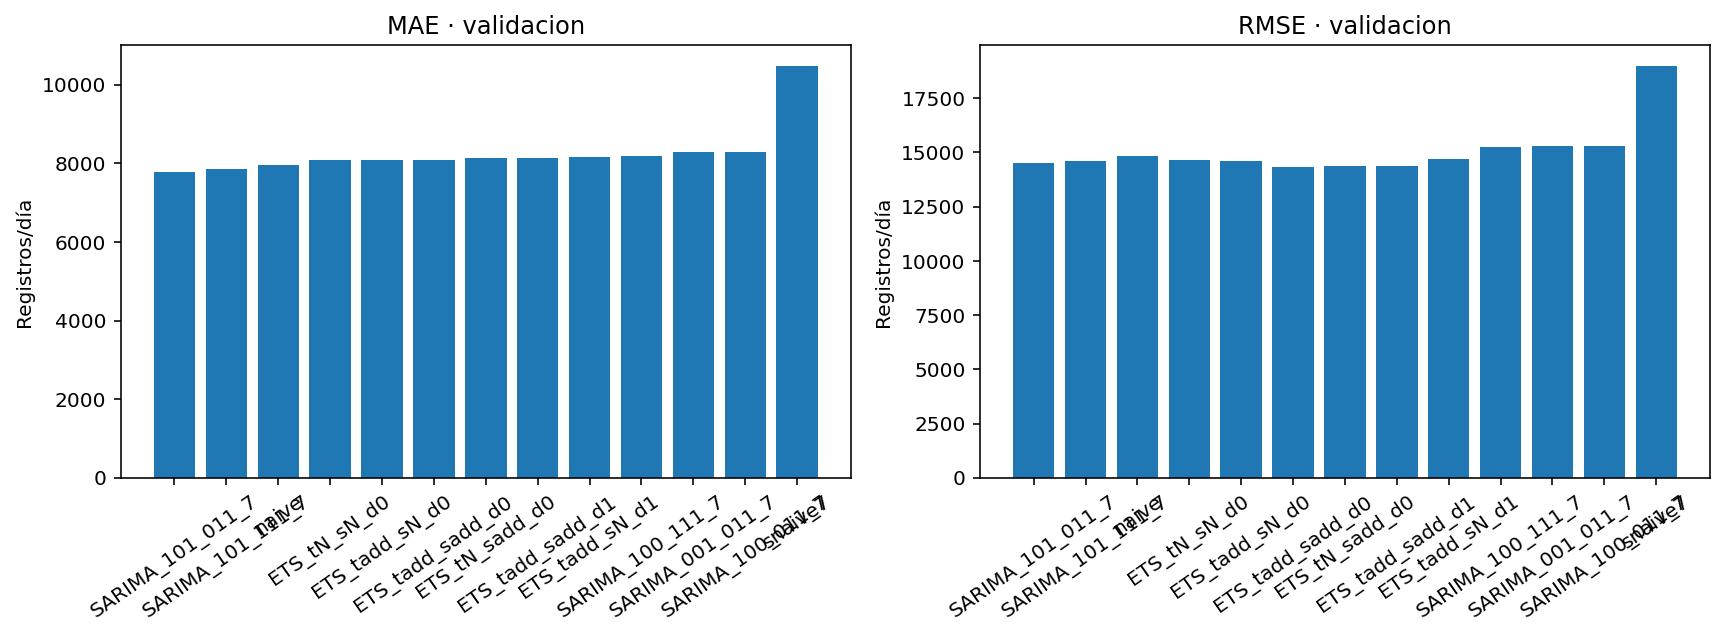

### Error de test

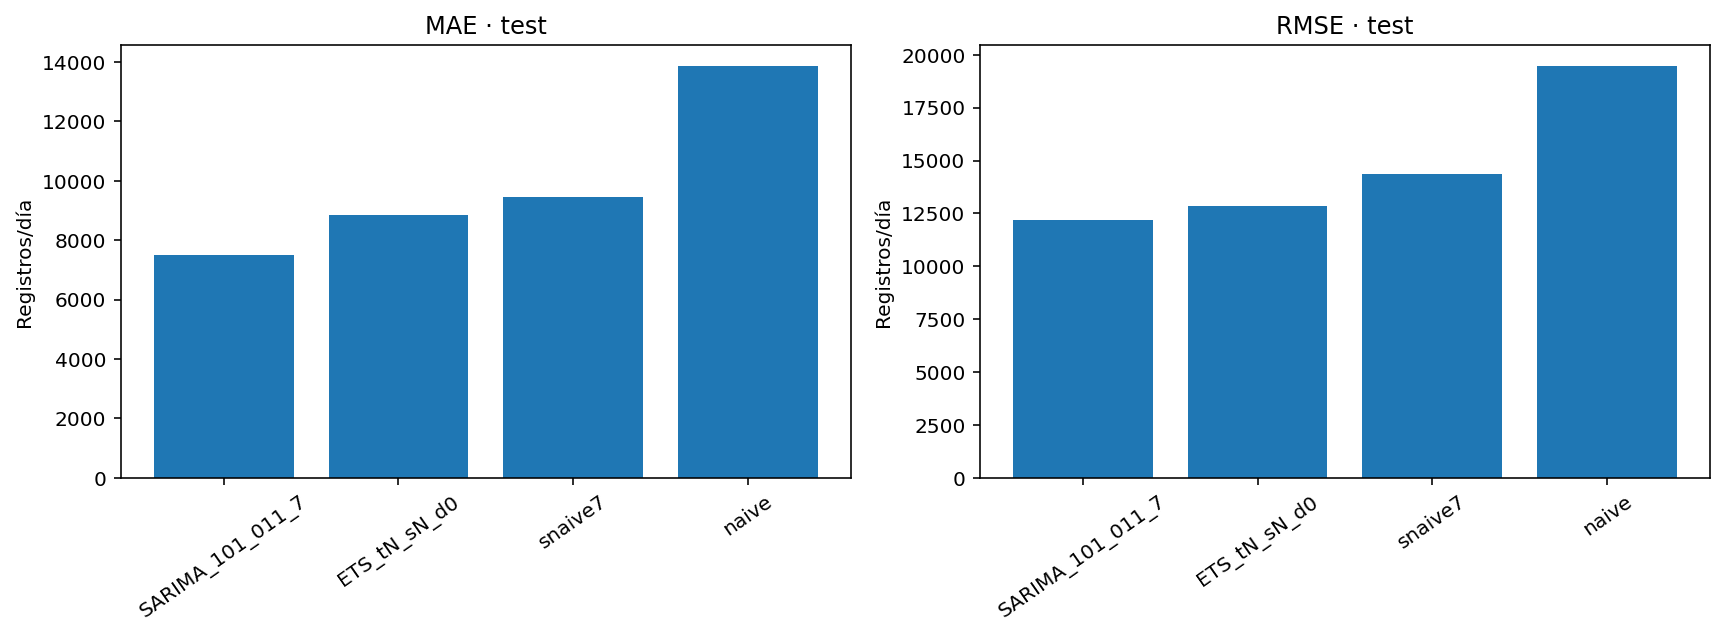

### Sensibilidades

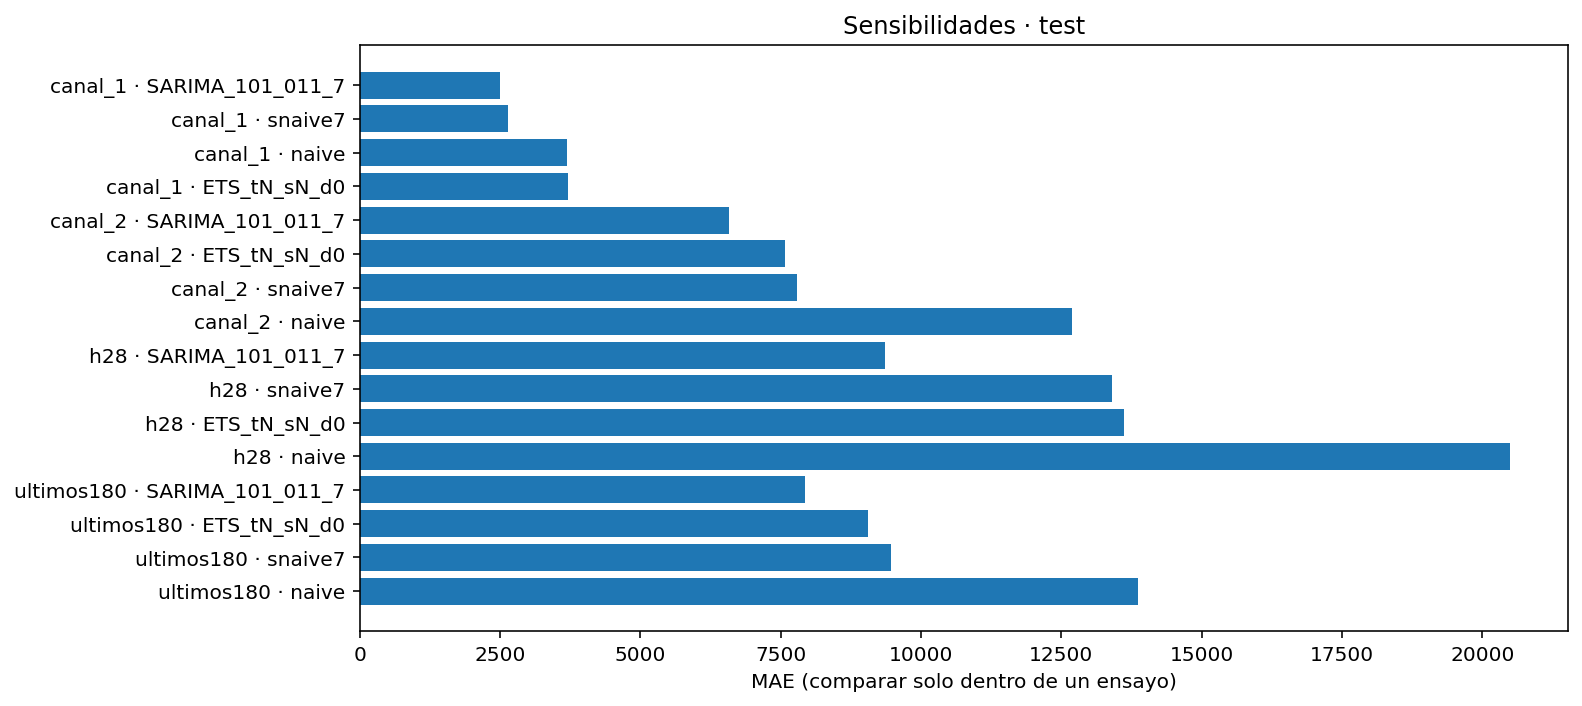

### Diagnósticos residuales

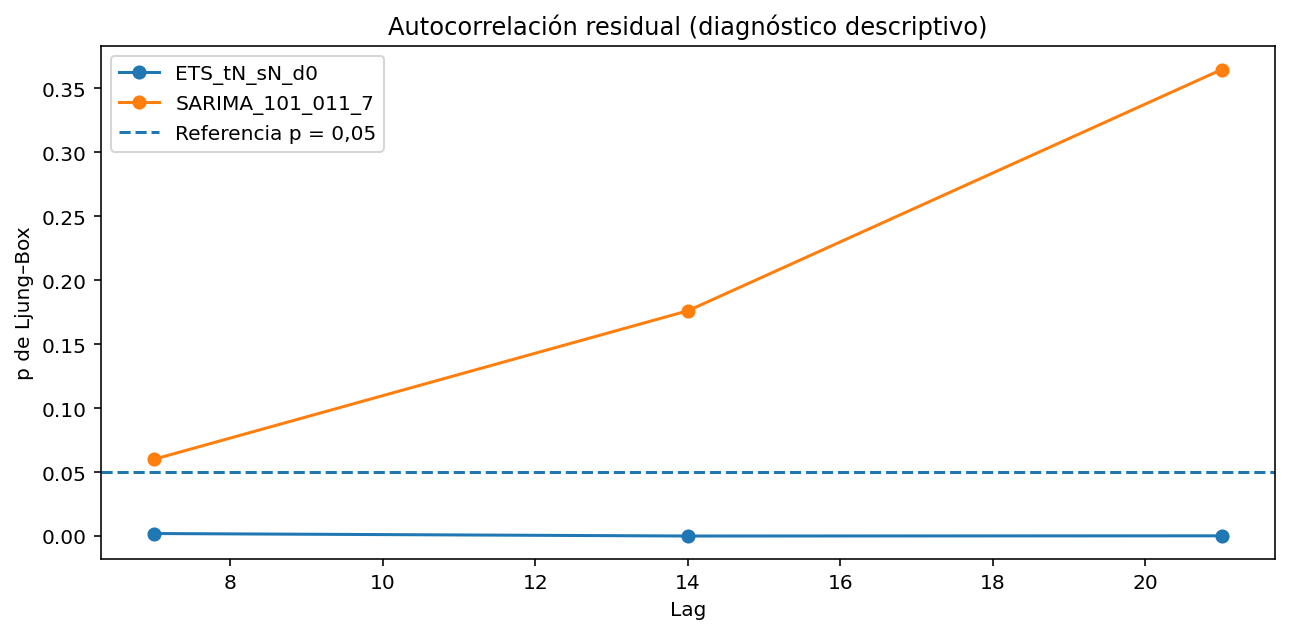

In [18]:
# Galería de resultados: se muestran LAS FIGURAS realmente generadas en la evaluación.
from IPython.display import display, Markdown, Image
from pathlib import Path
import pandas as pd
figuras=[('Error de validación', 'md3_evaluacion_validacion.png'), ('Error de test', 'md3_evaluacion_test.png'), ('Sensibilidades', 'md3_evaluacion_sensibilidades.png'), ('Diagnósticos residuales', 'md3_diagnosticos_residuos.png')]
tablas=[('Modelos y error de validación/test', 'md3_evaluacion_comparativa_semana12.csv'), ('Decisión congelada', 'md3_candidatos.csv'), ('Sensibilidad a escenarios', 'md3_sensibilidad.csv'), ('Diagnóstico de residuos', 'md3_diagnosticos_residuos.csv')]
for titulo, nombre in tablas:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>10:
        display(Markdown('### '+titulo))
        tabla=pd.read_csv(archivo)
        if len(tabla):display(tabla.head(18).round(4))
    else:display(Markdown(f'**Pendiente:** {titulo} (no se generó {nombre})'))
for titulo,nombre in figuras:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>100:
        display(Markdown('### '+titulo));display(Image(filename=str(archivo)))
    else: display(Markdown(f'**Figura pendiente:** {titulo}'))


## 9. Validación final y controles de generalización

Revisión de resultados retenidos, sensibilidad y estados P01–P04, sin utilizar test para reoptimizar hiperparámetros.


In [19]:
display(Markdown('**Decisión congelada en validación:** '+str(json.loads((OUT/'seleccion_congelada.json').read_text()).get('recomendacion_validacion')) if (OUT/'seleccion_congelada.json').exists() else '**Selección pendiente**'))

**Decisión congelada en validación:** naive

## 10. Interpretación científica y limitaciones

Naive elegido por validación puede no vencer en test; se reporta la diferencia sin cambiar retrospectivamente la selección.


## 11. Persistencia del modelo y prueba de recarga

Guardar artefactos privados **reutilizables**, probar recarga y distinguir resultados experimentales de refits de uso posterior. No publicar el ZIP privado en GitHub.


In [20]:
# Persistir baseline y refits de finalistas; no rehacer búsqueda ni rolling-origin.
# Los refits se realizan exclusivamente sobre desarrollo + validación (primeros 623 días).
from pathlib import Path
import json, numpy as np, pandas as pd, time, traceback
from IPython.display import display,Markdown
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
MD_MODELS=OUT/'modelos';MD_MODELS.mkdir(parents=True,exist_ok=True)
PERSISTENCIA={'objetivo':'MD3','estado':'INCOMPLETO','modelos':{},'entrenamiento':'desarrollo+validacion; no test',
              'nota':'refits de persistencia independientes de los modelos por origen evaluados'}
if 'BSTAR' in globals() and 'serie' in globals() and len(serie)>=623:
    state={'modelo_seleccionado':BSTAR, 'fecha_ultimo_registro_historico':str(serie.fecha.iloc[-1].date()),
           'ultimos_7_registros':[float(z) for z in y[-7:]],'horizonte_validado':7,
           'origen':'historia completa posterior a evaluación; no sustituye test',
           'valor_futuro':'naive=último dato observado; snaive7=última semana'}
    (MD_MODELS/'baseline_estado.json').write_text(json.dumps(state,ensure_ascii=False,indent=2),encoding='utf-8')
    back=json.loads((MD_MODELS/'baseline_estado.json').read_text())
    assert float(back['ultimos_7_registros'][-1])==float(y[-1])
    PERSISTENCIA['modelos']['baseline']={'tipo':BSTAR,'verificado':True}
    frozen=OUT/'seleccion_congelada.json'
    if frozen.is_file():
        configs=json.loads(frozen.read_text())
        errors=[]
        for familia in ('ETS','SARIMA'):
            nombre=configs.get(familia)
            if not nombre:continue
            cfg=CONFIG[nombre]
            inicio=time.monotonic()
            print('[PERSISTENCIA MD3] refit',nombre,'sobre primeros 623 dias',flush=True)
            try:
                history=np.asarray(y[:623],dtype='float64')
                if familia=='ETS':
                    kw=dict(error='add',trend=cfg['trend'],seasonal=cfg['seasonal'],
                          damped_trend=cfg['damped'],initialization_method='estimated')
                    if cfg['seasonal']:kw['seasonal_periods']=7
                    trained=ETSModel(history,**kw).fit(maxiter=500,disp=False)
                    from statsmodels.tsa.exponential_smoothing.ets import ETSResultsWrapper
                    loader=ETSResultsWrapper.load
                else:
                    d=cfg['order'][1];D=cfg['seasonal_order'][1]
                    trained=SARIMAX(history,order=cfg['order'],seasonal_order=cfg['seasonal_order'],
                        trend='c' if d+D==0 else 'n',exog=None,simple_differencing=False,
                        use_exact_diffuse=True,enforce_stationarity=True,
                        enforce_invertibility=True,concentrate_scale=False).fit(method='lbfgs',maxiter=500,disp=False)
                    from statsmodels.tsa.statespace.sarimax import SARIMAXResultsWrapper
                    loader=SARIMAXResultsWrapper.load
                if not np.all(np.isfinite(trained.forecast(7))):raise ValueError('Pronostico no finito')
                file=MD_MODELS/(nombre+'.pkl');trained.save(str(file),remove_data=False)
                restored=loader(str(file)) # Archivo creado por ESTE notebook, no pickle externo.
                assert np.allclose(np.asarray(trained.forecast(7)),np.asarray(restored.forecast(7)),rtol=1e-7,atol=1e-5)
                PERSISTENCIA['modelos'][familia]={'nombre':nombre,'archivo':file.name,'verificado':True,'segundos':round(time.monotonic()-inicio,3)}
                print('[PERSISTENCIA MD3] verificado',nombre,flush=True)
            except Exception as exc:
                errors.append({'familia':familia,'modelo':nombre,'error':repr(exc)})
                print('[PERSISTENCIA MD3] INCOMPLETO',familia,repr(exc),flush=True)
        if errors:PERSISTENCIA['errores']=errors
        else:PERSISTENCIA['estado']='PERSISTIDO_REUTILIZABLE'
    else:PERSISTENCIA['estado']='PERSISTIDO_PARCIAL'
else:print('PERSISTENCIA INCOMPLETA: faltan serie o baseline en memoria')
(MD_MODELS/'estado_modelos.json').write_text(json.dumps(PERSISTENCIA,indent=2,ensure_ascii=False),encoding='utf-8')
display(Markdown('**Persistencia MD-3:** '+PERSISTENCIA['estado']))


[PERSISTENCIA MD3] refit ETS_tN_sN_d0 sobre primeros 623 dias
[PERSISTENCIA MD3] verificado ETS_tN_sN_d0
[PERSISTENCIA MD3] refit SARIMA_101_011_7 sobre primeros 623 dias
[PERSISTENCIA MD3] verificado SARIMA_101_011_7


**Persistencia MD-3:** PERSISTIDO_REUTILIZABLE

## 12. Auditoría y exportación de entregables

Primero se recalcula el inventario; luego se crean **dos ZIP separados** con manifiesto SHA-256 y comprobación de integridad. El notebook ejecutado se guarda por separado desde Kaggle.


In [21]:

FINAL_MD3=['md3_baselines_validacion.csv','md3_sarima_aicc.csv',
           'md3_candidatos.csv','seleccion_congelada.json',
           'md3_metricas_test.csv','md3_sensibilidad.csv',
           'md3_diagnosticos_residuos.csv','md3_semanas_observadas.csv']
missing=[n for n in FINAL_MD3 if not (OUT/n).exists()]
status='COMPLETO_PRELIMINAR' if not missing and not any(z['estado'] in ('INCOMPLETO','PAUSADO','PENDIENTE') for z in STATUS) else 'REQUIERE_REVISION'
save_json({'estado':status,'faltantes':missing,'eventos':STATUS},'md3_auditoria_entregables.json')
print('MD3:',status,'faltantes:',missing)


Guardado: /kaggle/working/hm_modelamiento/md3/md3_auditoria_entregables.json
MD3: COMPLETO_PRELIMINAR faltantes: []


In [22]:
# Exportación única: ZIP de evidencias público-revisable y ZIP de modelos PRIVADO.
# ZIP 1 excluye datos de clientes/Parquet, plantillas con descripciones y pesos binarios.
from pathlib import Path
from IPython.display import display,FileLink,Markdown
import hashlib,json,zipfile,datetime
OBJETIVO='md3'
ROOT=Path('/kaggle/working') if Path('/kaggle/working').is_dir() else OUT.parent.parent
ROOT.mkdir(parents=True,exist_ok=True)
MODEL_DIR=OUT/'modelos'
def sha_file(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(4*2**20),b''):h.update(b)
    return h.hexdigest()
def empaquetar(files,zfile,root,privado):
    manifest={'objetivo':OBJETIVO,'privado':privado,'generado_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
              'archivos':[]}
    with zipfile.ZipFile(zfile,'w',zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
        for j,p in enumerate(files,1):
            name=str(p.relative_to(root)).replace('\\','/')
            z.write(p,arcname=f'{OBJETIVO}/{name}')
            manifest['archivos'].append({'ruta':name,'tamano_bytes':p.stat().st_size,'sha256':sha_file(p)})
            if j%10==0 or j==len(files):print(f'[ZIP {"MODELOS" if privado else "EVIDENCIAS"}] {j}/{len(files)} archivos',flush=True)
        z.writestr(f'{OBJETIVO}/manifest_exportacion.json',json.dumps(manifest,ensure_ascii=False,indent=2))
    with zipfile.ZipFile(zfile) as check:
        assert check.testzip() is None
        assert f'{OBJETIVO}/manifest_exportacion.json' in check.namelist()
    return manifest
allowed={'.csv','.json','.jsonl','.png','.md','.svg','.txt'}
exclude_names={'referencia_seleccion.csv','referencia_test.csv','md4_consultas_holdout.csv',
               'md4_consultas_ajuste.csv','md2_popularidad_articulos_desarrollo.csv','md4_plantilla_pps_ciega.csv','md4_plantilla_pps_todos_escenarios.csv'}
evidencias=sorted(p for p in OUT.rglob('*') if p.is_file() and not p.is_relative_to(MODEL_DIR)
   and p.suffix.lower() in allowed and p.name not in exclude_names
   and not p.name.startswith('md4_pps_evaluaciones')
   and not any(part in {'cache_ajustes','incidencia','cache','temp','tmp'} for part in p.relative_to(OUT).parts))
modelos=sorted(p for p in MODEL_DIR.rglob('*') if p.is_file()) if MODEL_DIR.exists() else []
zip_e=ROOT/f'HM_{OBJETIVO.upper()}_Evidencias.zip'
zip_m=ROOT/f'HM_{OBJETIVO.upper()}_Modelos_PRIVADO.zip'
man_e=empaquetar(evidencias,zip_e,OUT,False)
man_m=empaquetar(modelos,zip_m,OUT,True)
assert zip_e.exists() and zip_m.exists() and len(man_e['archivos'])>0 and len(man_m['archivos'])>0
print('EVIDENCIAS:',zip_e,round(zip_e.stat().st_size/2**20,2),'MiB')
print('MODELOS PRIVADOS:',zip_m,round(zip_m.stat().st_size/2**20,2),'MiB')
display(Markdown('**Descarga 1 — Evidencias de modelado y evaluación**'))
display(FileLink(str(zip_e)))
display(Markdown('**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**'))
display(FileLink(str(zip_m)))


[ZIP EVIDENCIAS] 10/32 archivos
[ZIP EVIDENCIAS] 20/32 archivos
[ZIP EVIDENCIAS] 30/32 archivos
[ZIP EVIDENCIAS] 32/32 archivos
[ZIP MODELOS] 4/4 archivos
EVIDENCIAS: /kaggle/working/HM_MD3_Evidencias.zip 2.56 MiB
MODELOS PRIVADOS: /kaggle/working/HM_MD3_Modelos_PRIVADO.zip 9.92 MiB


**Descarga 1 — Evidencias de modelado y evaluación**

/kaggle/working/HM_MD3_Evidencias.zip

**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**

/kaggle/working/HM_MD3_Modelos_PRIVADO.zip

## 13. Conclusiones y estado de cierre

Las conclusiones siguientes se generan a partir de los archivos de evaluación y persistencia, no de una declaración estática.


In [23]:
# Cierre ejecutivo derivado de archivos realmente generados.
from IPython.display import display,Markdown
import json
estado_path=OUT/'md3_estado_semana12.json'
eval_state=json.loads(estado_path.read_text()) if estado_path.is_file() else {'estado':'SIN_EVALUACION'}
model_path=OUT/'modelos'/'estado_modelos.json'
mod_state=json.loads(model_path.read_text()) if model_path.is_file() else {'estado':'SIN_PERSISTENCIA'}
pend=[f"{i.get('prueba','?')}: {i.get('estado')}" for i in eval_state.get('pruebas',[])
      if i.get('estado') not in ('PASS','EVALUADO')]
texto=(f'### Resultado final — MD-3\n'
      f'- **Modelado y evaluación:** `{eval_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Persistencia reutilizable:** `{mod_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Pruebas con reservas:** {", ".join(pend) if pend else "sin pendientes reportados en el estado automatizado"}.\n'
      f'- **Entregables:** `HM_MD3_Evidencias.zip` y `HM_MD3_Modelos_PRIVADO.zip`.\n'
      '- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.\n')
display(Markdown(texto))


### Resultado final — MD-3
- **Modelado y evaluación:** `EVALUADO`.
- **Persistencia reutilizable:** `PERSISTIDO_REUTILIZABLE`.
- **Pruebas con reservas:** sin pendientes reportados en el estado automatizado.
- **Entregables:** `HM_MD3_Evidencias.zip` y `HM_MD3_Modelos_PRIVADO.zip`.
- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.
